# Question 6: 

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.mixture import GaussianMixture


def generate_data(n_samples, means, variances, weights, random_state):
    np.random.seed(random_state)

    X = np.zeros((n_samples, 1))
    true_labels = np.zeros(n_samples, dtype=int)
    K = len(weights)

    cluster_indices = np.random.choice(range(K), size=n_samples, p=weights)

    for k in range(K):
        num_k = np.sum(cluster_indices == k)
        if num_k > 0:
            X[cluster_indices == k, 0] = np.random.normal(means[k], np.sqrt(variances[k]), num_k)
            true_labels[cluster_indices == k] = k

    return X, true_labels


def plot_data(X, labels, means, variances, weights, title="Data"):
    x = X[:, 0]
    grid = np.linspace(x.min() - 2, x.max() + 2, 1000)
    jitter = np.random.default_rng(0).uniform(-0.01, 0.01, len(x))

    pdfs = [weights[k] * norm.pdf(grid, means[k], np.sqrt(variances[k])) for k in range(len(means))]

    plt.figure(figsize=(10, 4))
    plt.plot(grid, np.sum(pdfs, axis=0), color='gray', lw=5, alpha=0.4, label="mixture density")
    plt.scatter(x, jitter - 0.03, c=[f"C{l}" for l in labels], alpha=0.5, s=12)

    for k in range(len(means)):
        plt.plot(grid, pdfs[k], color=f"C{k}", lw=1.5,
                 label=f"comp {k}: mean={means[k]:.2f}, var={variances[k]:.2f}, weight={weights[k]:.2f}")
        plt.scatter(means[k], 0, marker='x', s=200, color='red')

    plt.title(title)
    plt.xlabel("f1")
    plt.ylabel("density")
    plt.legend(fontsize=8)
    plt.show()


def assignment_accuracy(true_labels, predicted_labels, K):
    # GMM component numbers are arbitrary, so score the best matching of components to true classes
    return max(
        np.mean(np.array(perm)[predicted_labels] == true_labels)
        for perm in itertools.permutations(range(K))
    )


def run_gmm(X, true_labels, means_init, variances_init, weights_init, title):
    K = len(means_init)
    gmm = GaussianMixture(
        n_components=K,
        covariance_type='full',
        means_init=np.array(means_init, dtype=float).reshape(-1, 1),
        precisions_init=(1 / np.array(variances_init, dtype=float)).reshape(-1, 1, 1),
        weights_init=np.array(weights_init, dtype=float),
        n_init=1,
        max_iter=1000,
        tol=1e-8,
    )
    gmm.fit(X)

    predicted_labels = gmm.predict(X)
    est_means = gmm.means_.ravel()
    est_vars = gmm.covariances_.ravel()
    est_weights = gmm.weights_

    print(pd.DataFrame({
        'init mean': means_init,
        'init var': variances_init,
        'init weight': weights_init,
        'est mean': est_means.round(3),
        'est var': est_vars.round(3),
        'est weight': est_weights.round(3),
    }))
    print(f"converged: {gmm.converged_} after {gmm.n_iter_} EM iterations")
    print(f"average log-likelihood: {gmm.score(X):.4f}")
    print(f"assignment accuracy vs. true labels: {assignment_accuracy(true_labels, predicted_labels, K):.3f}")

    plot_data(X, predicted_labels, est_means, est_vars, est_weights, title=title)
    return gmm

## Sample data


(600, 1) (600,)
0    181
1    233
2    186
Name: count, dtype: int64


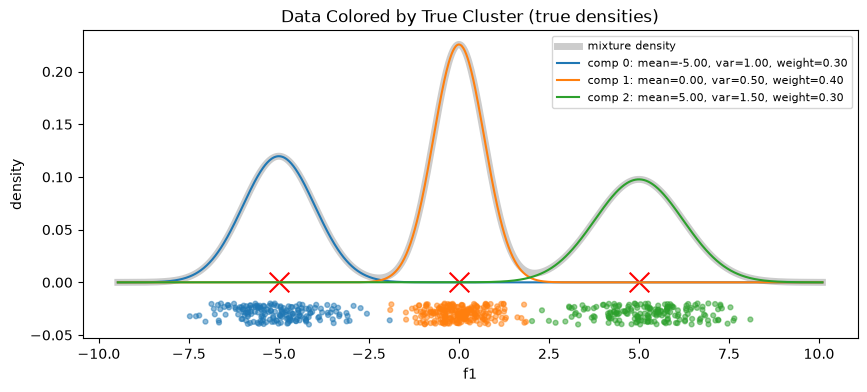

In [3]:
true_means = [-5.0, 0.0, 5.0]
true_variances = [1.0, 0.5, 1.5]
true_weights = [0.3, 0.4, 0.3]

X, true_labels = generate_data(
    n_samples=600,
    means=true_means,
    variances=true_variances,
    weights=true_weights,
    random_state=42
)

print(X.shape, true_labels.shape)
print(pd.Series(true_labels).value_counts().sort_index())
plot_data(X, true_labels, true_means, true_variances, true_weights,
          title="Data Colored by True Cluster (true densities)")

## (a) EM correctly infers the original assignments



   init mean  init var  init weight  est mean  est var  est weight
0       -4.0       1.0     0.333333    -5.050    0.967       0.300
1        1.0       1.0     0.333333    -0.001    0.495       0.389
2        4.0       1.0     0.333333     5.227    1.399       0.310
converged: True after 9 EM iterations
average log-likelihood: -2.4110
assignment accuracy vs. true labels: 0.997


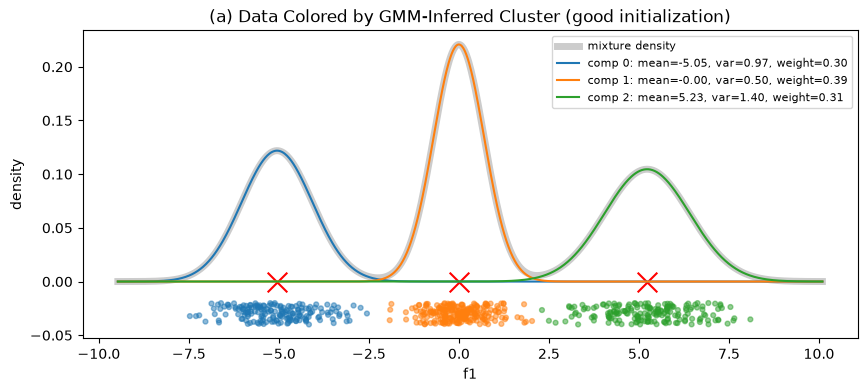

In [4]:
gmm_good = run_gmm(
    X, true_labels,
    means_init=[-4.0, 1.0, 4.0],
    variances_init=[1.0, 1.0, 1.0],
    weights_init=[1/3, 1/3, 1/3],
    title="(a) Data Colored by GMM-Inferred Cluster (good initialization)"
)

## (b) EM gets stuck in a local optimum

Same data, but a bad initialization

   init mean  init var  init weight  est mean  est var  est weight
0       -5.5       0.5     0.333333    -5.330    0.660       0.226
1       -4.5       0.5     0.333333    -4.482    0.066       0.021
2        2.5      10.0     0.333333     1.870    9.846       0.752
converged: True after 869 EM iterations
average log-likelihood: -2.6932
assignment accuracy vs. true labels: 0.657


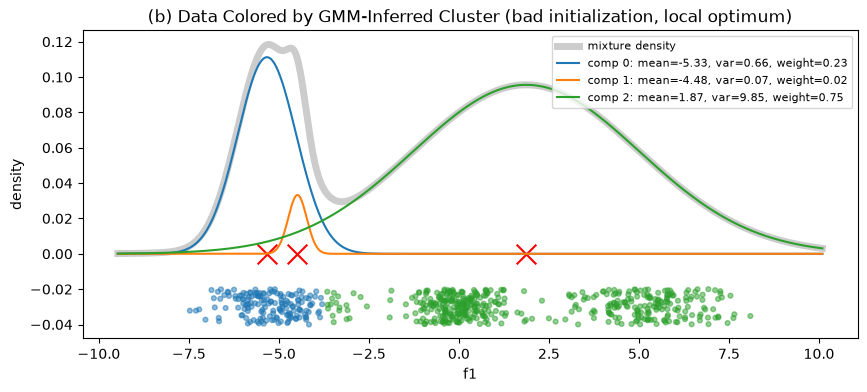

In [5]:
gmm_bad = run_gmm(
    X, true_labels,
    means_init=[-5.5, -4.5, 2.5],
    variances_init=[0.5, 0.5, 10.0],
    weights_init=[1/3, 1/3, 1/3],
    title="(b) Data Colored by GMM-Inferred Cluster (bad initialization, local optimum)"
)